# Part F — Haslam and the sky models against the power-law prediction

| | |
|---|---|
| **Reads** | `paper_outputs/pipeline/step5_fit/` (`fits/`, `ring_ra.npy`), `paper_outputs/pipeline/step2_ring_tods/``sky_tods.npz`, `paper_outputs/pipeline/step6_predict_408/``scale_offset_408.csv` |
| **Writes** | `test_outputs/plot3_haslam_vs_fit/` (figures) |
| **Feeds the paper** | figures only: `tab:scale-offset` and the ratio in main.tex:647 are step 6's `scale_offset_408.csv` (this Part's stored Summary says 0.81–0.98, the paper 0.97) |

**Pipeline:** the scale-offset fit is pipeline step 6 (`scale_offset_408.csv`). This Part reads that table and plots it; it no longer refits (since 2026-11-17: its own fit gave the same table to 1e-15). The stored outputs are from its own fit.

## Haslam 408 MHz against the power-law SED fit along the TRIS ring

**Purpose.** Test the Haslam 408 MHz map against our best-fit SED along the TRIS ring. The best fit is
the **power law** (pipeline step 4's selection; Part D's decision sheet); no other spectral model is fitted or
shown. The power law's pivot is 408 MHz, so its amplitude `A_K` is the 408 MHz temperature it
predicts at each ring sample from the other surveys (TRIS 600/820, LWA1 35/80, Maipu 45,
Stockert 1420; **Haslam is not a fit point**).

For every sky model at 408 MHz (Haslam and the six models of pipeline step 2), a straight line is fitted
to model against prediction along the ring, with the errors-in-variables fit of Part E
(York et al. 2004):

$$T_\mathrm{model} = a\,T_\mathrm{PL} + b.$$

The slope $a$ is the scale and the intercept $b$ the offset; perfect agreement is $(a, b) = (1, 0)$.

* **Figure 1:** Haslam (uncorrected, Carter, Irfan) against the power-law prediction, T–T.
* **Figure 2:** all seven models in the scale–offset plane.
* **Figure 3:** model / prediction along the ring for the three Haslam versions.
* **Table:** a, b, χ²/ν and the ratio for every model, with all samples and with Cygnus A excluded.

All temperatures are Rayleigh–Jeans with the CMB removed, through the TRIS beam.

> **Caveats.**
> * **Correlated samples.** The 120 ring samples are 3° apart under a ~20° beam, so they are correlated.
>   Every σ here is an underestimate, by roughly √(120/18) ≈ ×2.6.
> * **Haslam's error.** It is mostly a common scale and zero-level term (10% ⊕ 3 K), but it is treated
>   here as independent per sample.
> * **The prediction.** The power law's 408 MHz value is an interpolation between LWA1 80 and TRIS 600,
>   so it is only as good as that fit. Spectral curvature, if present, would change it; that is not
>   tested here.
> * **Scale and offset.** The intercept absorbs any zero-level offset between the two axes: the slope
>   is the scale, the intercept the offset.
> * **No causes.** The text describes positions and sizes only.

**Inputs** (read only), from the pipeline's products (`paper_outputs/pipeline/step5_fit/`, `step2_ring_tods/`):
`fits/unitNNN__power_law.npz` (the power-law fit per ring sample), `sky_tods.npz` (the seven models at
408 MHz through the TRIS beam, with beam coverage) and `ring_ra.npy` (the RA of each sample).
Figures and CSVs go to `paper_outputs/plot3_haslam_vs_fit/`. Rerun: Restart & Run All (seconds).

In [1]:
%matplotlib inline
import time as _nb_time; _NB_T0 = _nb_time.time()   # notebook run time, printed by the last cell
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Ellipse

REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "configs" / "run_pipeline.yaml").exists())
PIPE2 = REPO / "paper_outputs" / "pipeline" / "step2_ring_tods"   # run_pipeline.py step 2 (ring TODs), read only
PIPE5 = REPO / "paper_outputs" / "pipeline" / "step5_fit"         # run_pipeline.py step 5 (our model's fits), read only
OUT_DIR = REPO / "test_outputs" / "plot3_haslam_vs_fit"   # a check: the paper table is step 6's
HASLAM_FILE = "HASLAM_DESTRIPED_ONLY.fits"

COV_MIN = 0.5              # a model sample is kept when its beam coverage >= this (as the pipeline)
CYG_A_RA, CYG_HALF = 299.9, 25.0     # Cygnus A and the half-width of the excluded / shaded window [deg]

# sky_tods.npz order: 0 Haslam, 1 Carter, 2 Irfan, 3 GSM2008, 4 GSM2016, 5 GINAN, 6 LFSM
MODELS = ["Haslam (uncorrected)", "Haslam, Carter correction", "Haslam, Irfan correction",
          "GSM2008", "GSM2016", "GSM2016, GINAN correction", "LFSM"]
HASLAMS = MODELS[:3]
SHORT = {"Haslam (uncorrected)": "Haslam", "Haslam, Carter correction": "Haslam + Carter",
         "Haslam, Irfan correction": "Haslam + Irfan", "GSM2008": "GSM2008", "GSM2016": "GSM2016",
         "GSM2016, GINAN correction": "GSM2016 + GINAN", "LFSM": "LFSM"}
COLOUR = {"Haslam (uncorrected)": "#E69F00", "Haslam, Carter correction": "#56B4E9",
          "Haslam, Irfan correction": "#CC79A7"}            # Okabe-Ito; the rest grey

plt.rcParams.update({"figure.dpi": 110, "font.size": 24, "axes.titlesize": 24,
                     "axes.labelsize": 24, "legend.fontsize": 22, "figure.facecolor": "white"})
OUT_DIR.mkdir(exist_ok=True)

def save(fig, name):
    # Save a figure as PNG in OUT_DIR, then show it inline.
    fig.savefig(OUT_DIR / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.show()
    print(f"saved {(OUT_DIR / f'{name}.png').relative_to(REPO)}")

### 1. Inputs: the power-law prediction and the sky models

* **Prediction (x):** the maximum-likelihood `A_K` (`maxpoint`) of the power-law fit at each ring
  sample. Its error is the standard deviation of the posterior `A_K` samples stored with the fit.
* **Sky models (y):** each model's 408 MHz ring TOD from `sky_tods.npz`, kept where its beam coverage is
  ≥ `COV_MIN`. The y error is Haslam's error from `sed_prototype.sigma_for` (10% scale ⊕ 3 K zero
  level, as in Part E), evaluated at each model's own temperature. The same rule is used for all
  seven models, which all use Haslam at 408 MHz, so their fits can be compared directly.

In [2]:
sys.dont_write_bytecode = True
sys.path.insert(0, str(REPO / "src"))
from moonrunes.sed_prototype import sigma_for

RA = np.load(PIPE5 / "ring_ra.npy")
N = RA.size

z = np.load(PIPE2 / "sky_tods.npz", allow_pickle=False)
names = [str(n) for n in z["names"]]
assert names == MODELS, names
T_MOD, S_MOD = {}, {}
for i, n in enumerate(names):
    T_MOD[n] = np.where(z[f"cov_{i}"] >= COV_MIN, z[f"tod_{i}"], np.nan)
    S_MOD[n] = np.asarray(sigma_for(dict(freq_mhz=408.0, file=HASLAM_FILE), T_MOD[n]), dtype=float)

A_PL, S_PL = np.full(N, np.nan), np.full(N, np.nan)
for u in range(N):
    p = PIPE5 / "fits" / f"unit{u:03d}__power_law.npz"
    if not p.exists():
        continue
    r = np.load(p, allow_pickle=False)
    iA = [str(x) for x in r["names"]].index("A_K")
    A_PL[u] = float(r["maxpoint"][iA])
    if "samples" in r.files:
        S_PL[u] = float(np.std(r["samples"][:, iA]))
print(f"power law: {np.isfinite(A_PL).sum()} of {N} samples; median A(408) {np.nanmedian(A_PL):.2f} K, "
      f"median posterior σ {np.nanmedian(S_PL):.3f} K ({100 * np.nanmedian(S_PL / A_PL):.2f}%)")
print(pd.DataFrame({"samples (coverage ≥ 0.5)": [int(np.isfinite(T_MOD[n]).sum()) for n in MODELS],
                    "median T [K]": [np.nanmedian(T_MOD[n]) for n in MODELS],
                    "median σ [K]": [np.nanmedian(S_MOD[n]) for n in MODELS]},
                   index=MODELS).round(3).to_string())

power law: 120 of 120 samples; median A(408) 32.15 K, median posterior σ 0.168 K (0.54%)
                           samples (coverage ≥ 0.5)  median T [K]  median σ [K]
Haslam (uncorrected)                            120        28.918         4.167
Haslam, Carter correction                       120        30.667         4.290
Haslam, Irfan correction                        120        22.734         3.764
GSM2008                                         120        28.911         4.166
GSM2016                                         120        31.333         4.338
GSM2016, GINAN correction                       120        32.797         4.445
LFSM                                            120        27.624         4.078


### 2. The errors-in-variables fit

The fit is pipeline step 6's (`moonrunes.pipeline.york`, read from `scale_offset_408.csv`): the York et al. (2004)
straight-line fit with uncorrelated errors on both axes, σ_a and σ_b multiplied by √(χ²/ν) when χ²/ν > 1, over the
samples where both are finite, once with all samples and once without RA within ±25° of Cygnus A (RA 299.9°). It
gives σ_a and σ_b but not their covariance.

In [3]:
# The scale-offset fits are pipeline step 6 (`python run_pipeline.py --step predict_408`, moonrunes.pipeline.step_predict_408:
# model = a P + b, York, errors on both axes, σ inflated by sqrt(χ²/ν) when > 1, with the same inputs as above).
# This Part reads them; it does not refit.
SO_CSV = REPO / "paper_outputs" / "pipeline" / "step6_predict_408" / "scale_offset_408.csv"
SO = pd.read_csv(SO_CSV)
assert set(SO["samples"]) == {"all", f"excluding Cygnus A ± {CYG_HALF:g}°"}, \
    f"step 6's Cygnus window is not ± {CYG_HALF:g}° (run_pipeline.yaml pipeline.predict_408)"
FIT = {(q["model"], q["samples"] != "all"): dict(a=q["slope a"], sa=q["σ_a"], b=q["intercept b [K]"], sb=q["σ_b [K]"],
                                                 chi2_dof=q["χ²/ν"], n=int(q["N samples"]), mean_ratio=q["mean ratio"],
                                                 median_ratio=q["median ratio"])
       for _, q in SO.iterrows()}
assert set(FIT) == {(n, ex) for n in MODELS for ex in (False, True)}, sorted(FIT)
print(f"scale-offset fits read from {SO_CSV.relative_to(REPO)}")

CYG = np.abs(RA - CYG_A_RA) <= CYG_HALF          # shaded in Figure 3
print(f"Cygnus window RA {CYG_A_RA - CYG_HALF:g}–{CYG_A_RA + CYG_HALF:g}°: {int(CYG.sum())} of {N} samples")


scale-offset fits read from paper_outputs/pipeline/step6_predict_408/scale_offset_408.csv
Cygnus window RA 274.9–324.9°: 17 of 120 samples


#### Figure 1 — Haslam against the power-law prediction

One panel per Haslam version: uncorrected, with the Carter correction (1.029 × Haslam + 0.91 K) and with
the Irfan correction (the 8.9 K monopole minus T_CMB, i.e. −6.2 K, subtracted from the CMB-removed Haslam).
The axes are shared. x is the power-law fit's 408 MHz prediction and y the Haslam ring TOD. The points
are the ring samples, coloured by RA, drawn without error bars (the fit uses them). The dashed line is
1:1 and the black line the errors-in-variables fit; its a, b, σ_a, σ_b and χ²/ν are in the table at the
end. **σ are underestimates**: correlated samples, and Haslam's error is a common term treated as
independent.

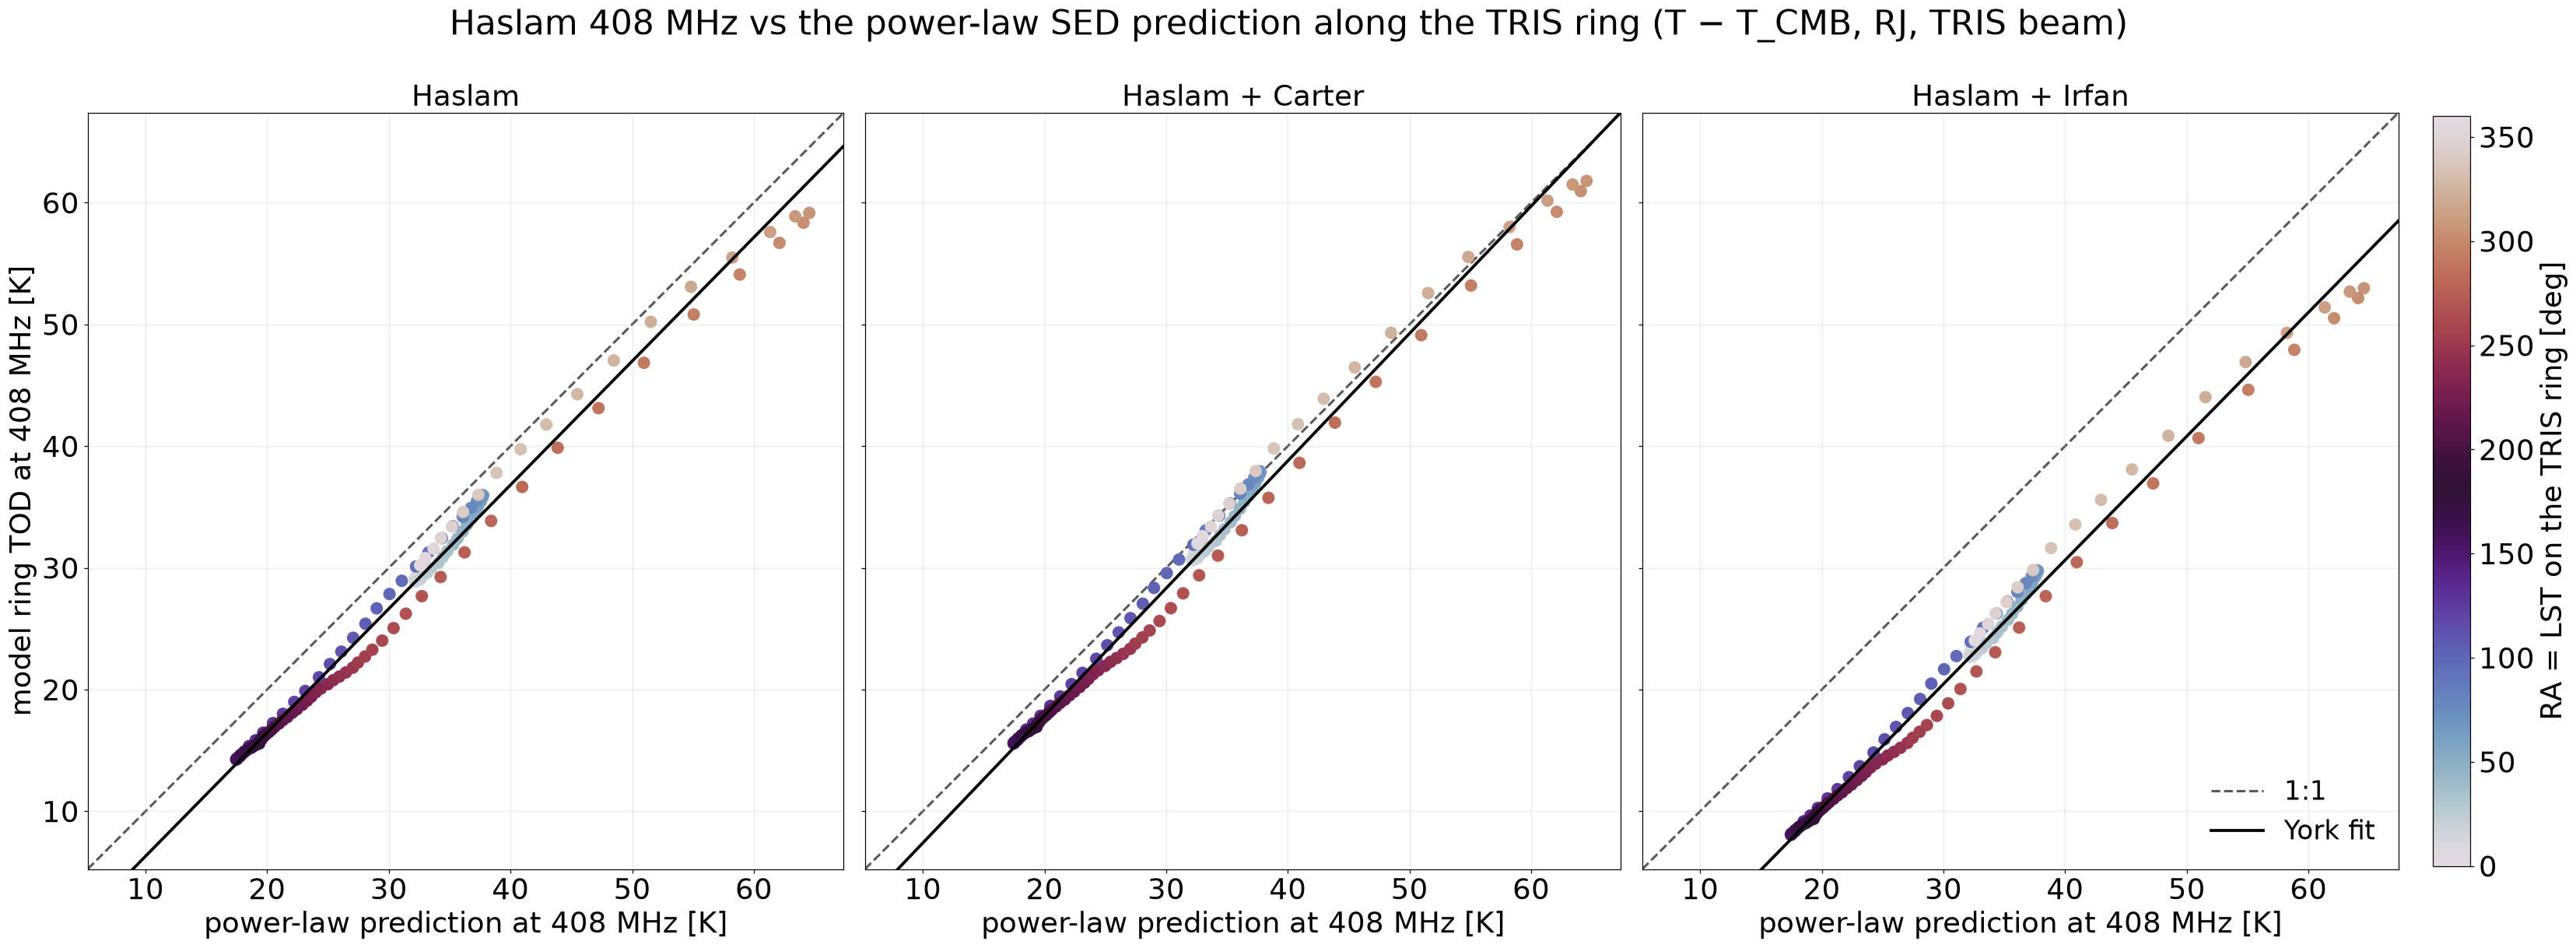

saved test_outputs/plot3_haslam_vs_fit/fig1_haslam_vs_power_law_tt.png


In [4]:
fig, axes = plt.subplots(1, 3, figsize=(30, 11), sharex=True, sharey=True, layout="constrained")
lo = np.nanmin([np.nanmin(A_PL)] + [np.nanmin(T_MOD[n]) for n in HASLAMS])
hi = np.nanmax([np.nanmax(A_PL)] + [np.nanmax(T_MOD[n]) for n in HASLAMS])
pad = 0.05 * (hi - lo)
lims = np.array([lo - pad, hi + pad])
for ax, n in zip(axes, HASLAMS):
    f = FIT[(n, False)]
    ok = np.isfinite(A_PL) & np.isfinite(T_MOD[n])
    sc = ax.scatter(A_PL[ok], T_MOD[n][ok], c=RA[ok], cmap="twilight", vmin=0, vmax=360, s=110, lw=0, zorder=2)
    ax.plot(lims, lims, color="0.35", ls="--", lw=2, label="1:1", zorder=1)
    ax.plot(lims, f["a"] * lims + f["b"], color="black", lw=2.5, label="York fit", zorder=3)
    ax.set_title(SHORT[n])
    ax.set_xlim(lims); ax.set_ylim(lims); ax.set_aspect("equal")
    ax.set_xlabel("power-law prediction at 408 MHz [K]")
    ax.grid(alpha=0.25)
axes[0].set_ylabel("model ring TOD at 408 MHz [K]")
axes[-1].legend(frameon=False, loc="lower right")
fig.colorbar(sc, ax=list(axes), shrink=0.85, pad=0.015, label="RA = LST on the TRIS ring [deg]")
fig.suptitle("Haslam 408 MHz vs the power-law SED prediction along the TRIS ring (T − T_CMB, RJ, TRIS beam)")
save(fig, "fig1_haslam_vs_power_law_tt")

#### Figure 2 — every sky model in the scale–offset plane

One point per model at (slope a, intercept b) from the same fit against the power-law prediction (all
samples). Each model has its own colour and marker, given in the legend; the Haslam versions are filled
with a black edge. The shaded 1σ ellipses have half-axes σ_a and σ_b. `york` does not return the a–b
covariance, so it is ignored and the ellipses are drawn untilted. Because the x values lie far from 0, a
and b are in fact strongly anti-correlated, so the true ellipses are tilted. The star is perfect
agreement, (1, 0). **Left:** the region around (1, 0), where six of the seven models lie. **Right:** the
full range, including GSM2016 + GINAN; the dashed box is the left panel. GSM2008 lies almost exactly on
uncorrected Haslam, so it is drawn as a smaller cross on top. **σ are underestimates** (correlated
samples).

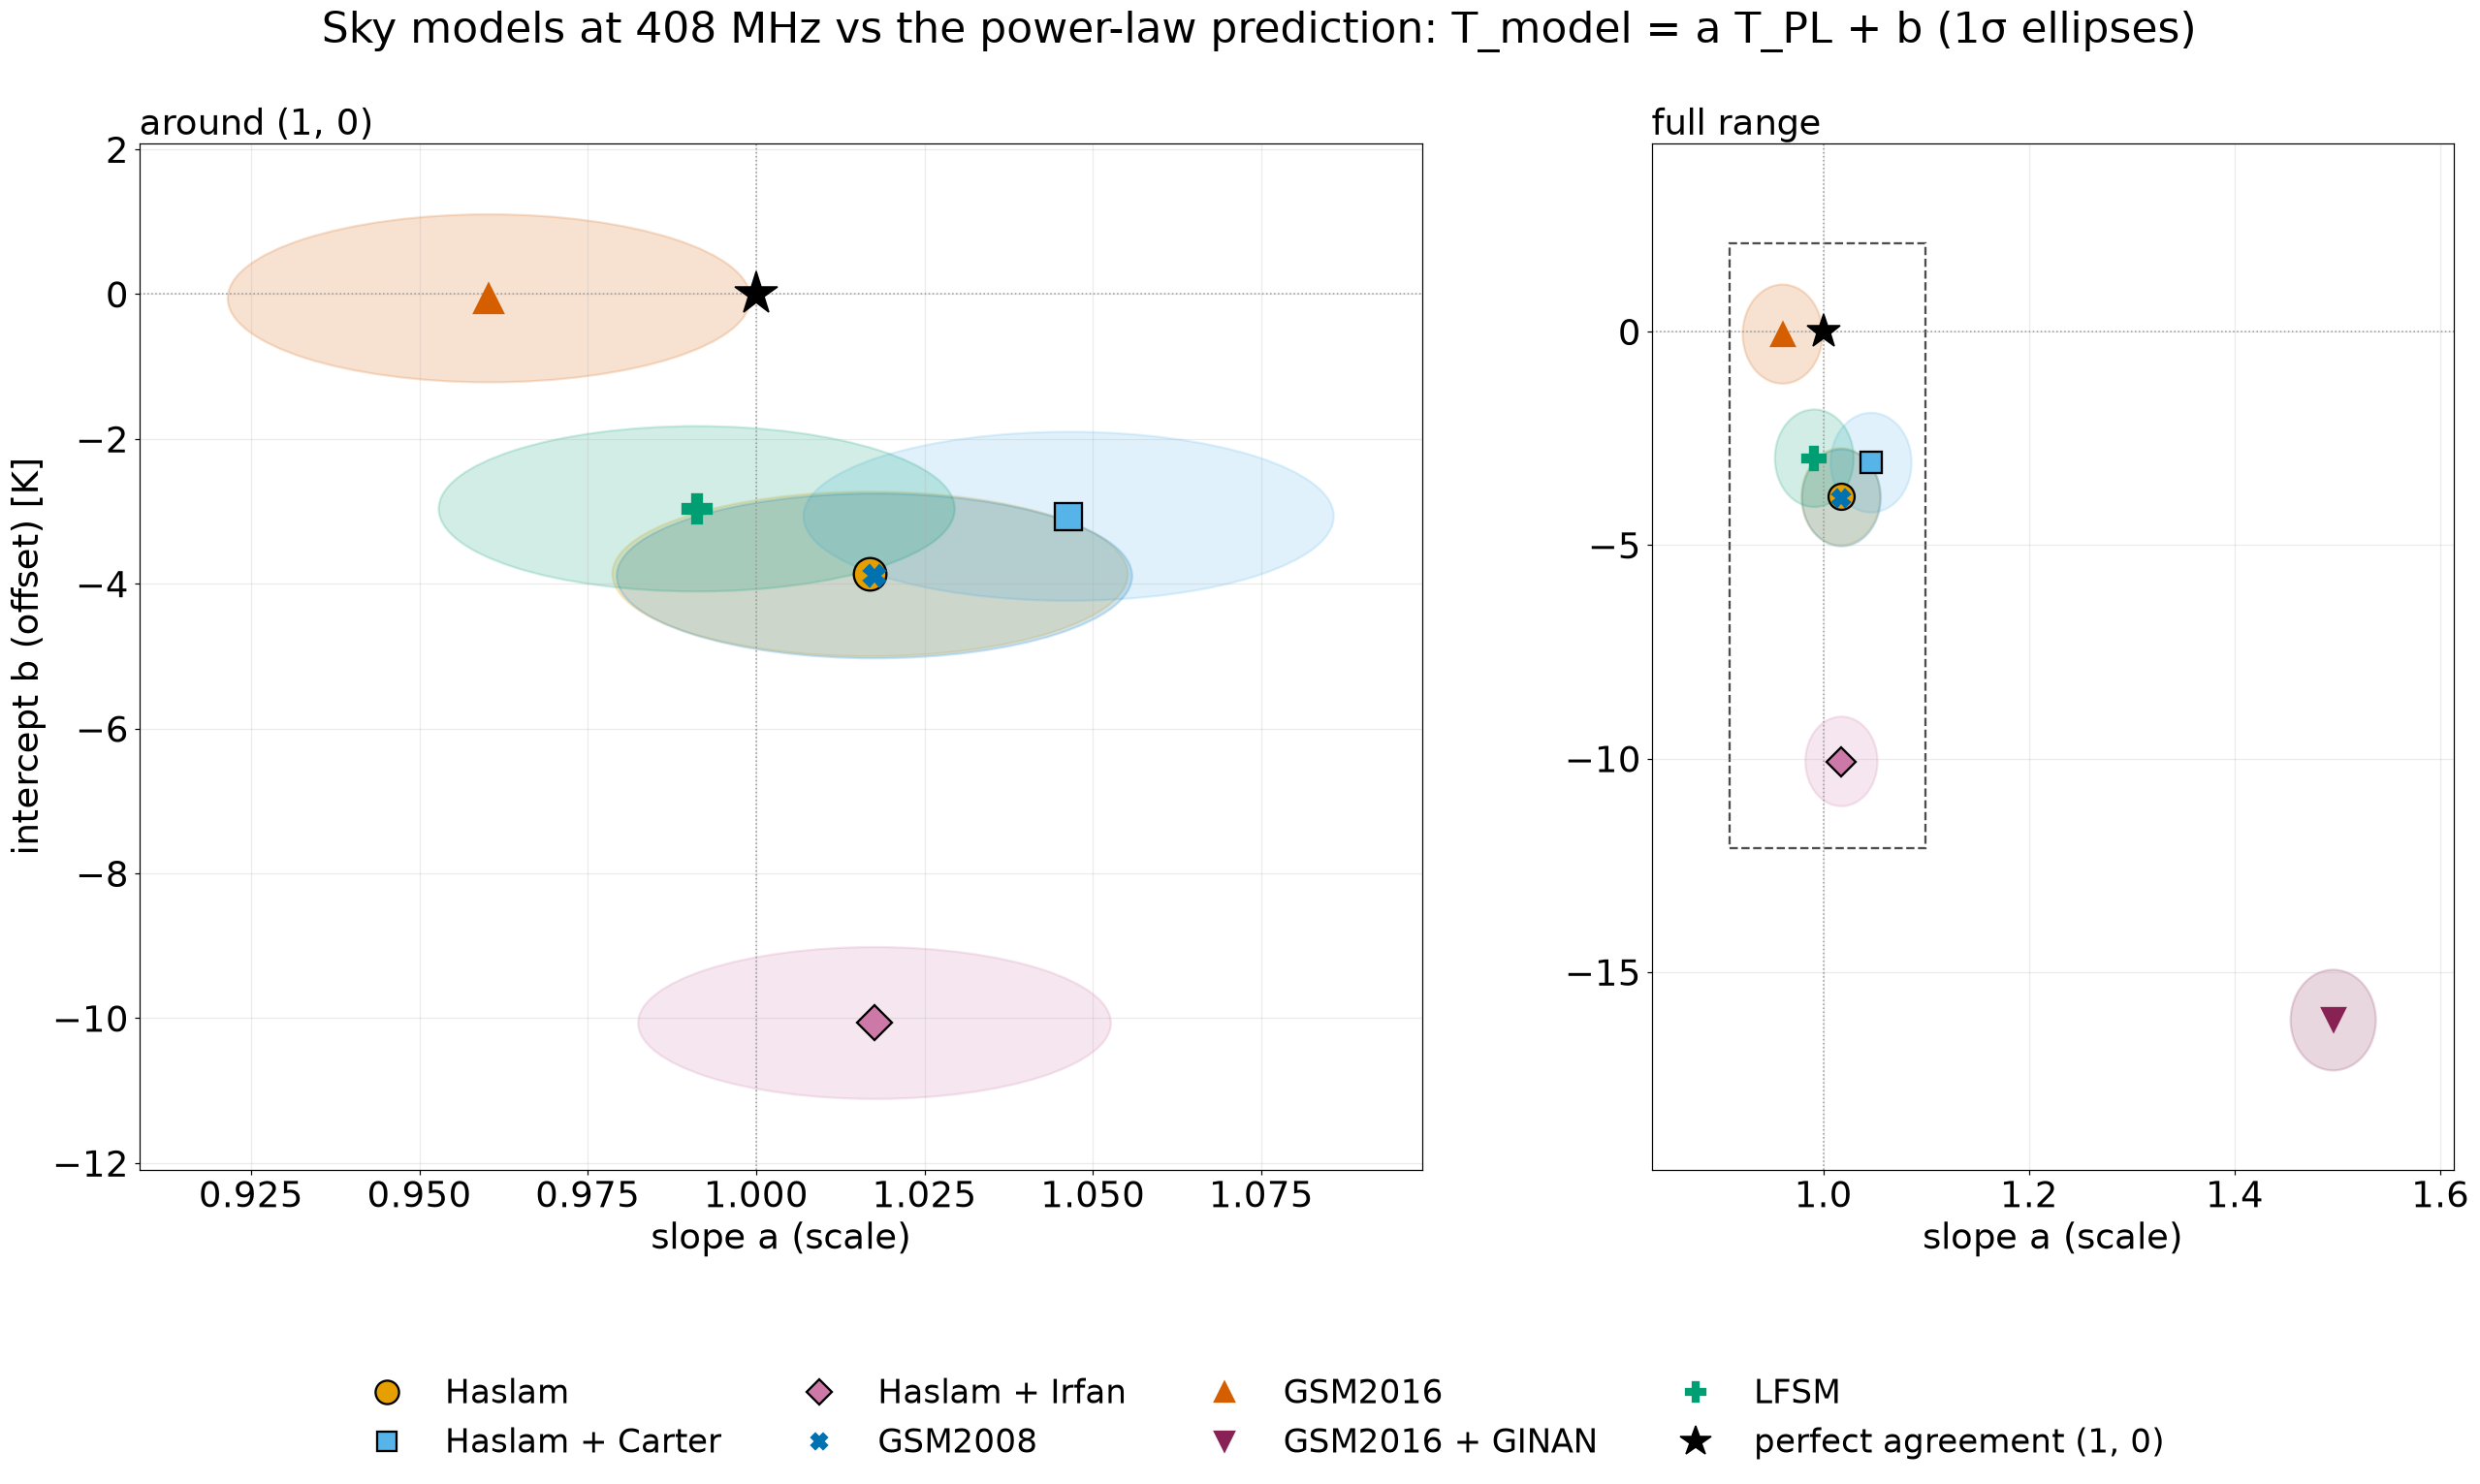

saved test_outputs/plot3_haslam_vs_fit/fig2_scale_offset_plane.png


In [5]:
STYLE = {   # Okabe-Ito colours (plus Tol's wine), one marker per model
    "Haslam (uncorrected)":      dict(color="#E69F00", marker="o", ms=22),
    "Haslam, Carter correction": dict(color="#56B4E9", marker="s", ms=18),
    "Haslam, Irfan correction":  dict(color="#CC79A7", marker="D", ms=17),
    "GSM2008":                   dict(color="#0072B2", marker="X", ms=14),   # sits on uncorrected Haslam
    "GSM2016":                   dict(color="#D55E00", marker="^", ms=19),
    "GSM2016, GINAN correction": dict(color="#882255", marker="v", ms=19),
    "LFSM":                      dict(color="#009E73", marker="P", ms=19),
}
ZOOM_OUT = ["GSM2016, GINAN correction"]                     # shown only in the full-range panel

def draw(ax, models, ms_scale=1.0):
    for n in models:
        f, st = FIT[(n, False)], STYLE[n]
        ax.add_patch(Ellipse((f["a"], f["b"]), 2 * f["sa"], 2 * f["sb"], fc=st["color"], ec=st["color"],
                             alpha=0.18, lw=1.5, zorder=1))
        ax.plot(f["a"], f["b"], ls="none", marker=st["marker"], ms=st["ms"] * ms_scale, color=st["color"],
                mec="black" if n in HASLAMS else st["color"], mew=1.5, zorder=4 if n == "GSM2008" else 3,
                label=SHORT[n])
    ax.plot(1, 0, ls="none", marker="*", ms=30 * ms_scale, color="black", zorder=5, label="perfect agreement (1, 0)")
    ax.axvline(1, color="0.6", lw=1, ls=":"); ax.axhline(0, color="0.6", lw=1, ls=":")
    ax.grid(alpha=0.25)

fig, (ax, axf) = plt.subplots(1, 2, figsize=(28, 12.5), gridspec_kw=dict(width_ratios=[1.6, 1], wspace=0.22))
near = [n for n in MODELS if n not in ZOOM_OUT]
draw(ax, near)
ea = np.array([[FIT[(n, False)]["a"] - FIT[(n, False)]["sa"], FIT[(n, False)]["a"] + FIT[(n, False)]["sa"]] for n in near] + [[1, 1]])
eb = np.array([[FIT[(n, False)]["b"] - FIT[(n, False)]["sb"], FIT[(n, False)]["b"] + FIT[(n, False)]["sb"]] for n in near] + [[0, 0]])
xr, yr = (ea.min(), ea.max()), (eb.min(), eb.max())
px, py = 0.08 * (xr[1] - xr[0]), 0.08 * (yr[1] - yr[0])
zx, zy = (xr[0] - px, xr[1] + px), (yr[0] - py, yr[1] + py)
ax.set_xlim(zx); ax.set_ylim(zy)
ax.set_xlabel("slope a (scale)"); ax.set_ylabel("intercept b (offset) [K]")
ax.set_title("around (1, 0)", loc="left")

draw(axf, MODELS, ms_scale=0.8)
axf.add_patch(plt.Rectangle((zx[0], zy[0]), zx[1] - zx[0], zy[1] - zy[0], fill=False, ec="0.3", ls="--", lw=1.5))
axf.margins(0.12)
axf.set_xlabel("slope a (scale)")
axf.set_title("full range", loc="left")

h, l = axf.get_legend_handles_labels()
fig.legend(h, l, loc="lower center", ncol=4, frameon=False, bbox_to_anchor=(0.5, -0.13), markerscale=0.9)
fig.suptitle("Sky models at 408 MHz vs the power-law prediction: T_model = a T_PL + b (1σ ellipses)", y=0.98)
save(fig, "fig2_scale_offset_plane")

#### Figure 3 — model / prediction along the ring

The 408 MHz TOD of each Haslam version divided by the power-law prediction, at every ring sample. The
horizontal line is a ratio of 1; the light shading is RA 299.9 ± 25° (Cygnus A), the window the table
excludes.

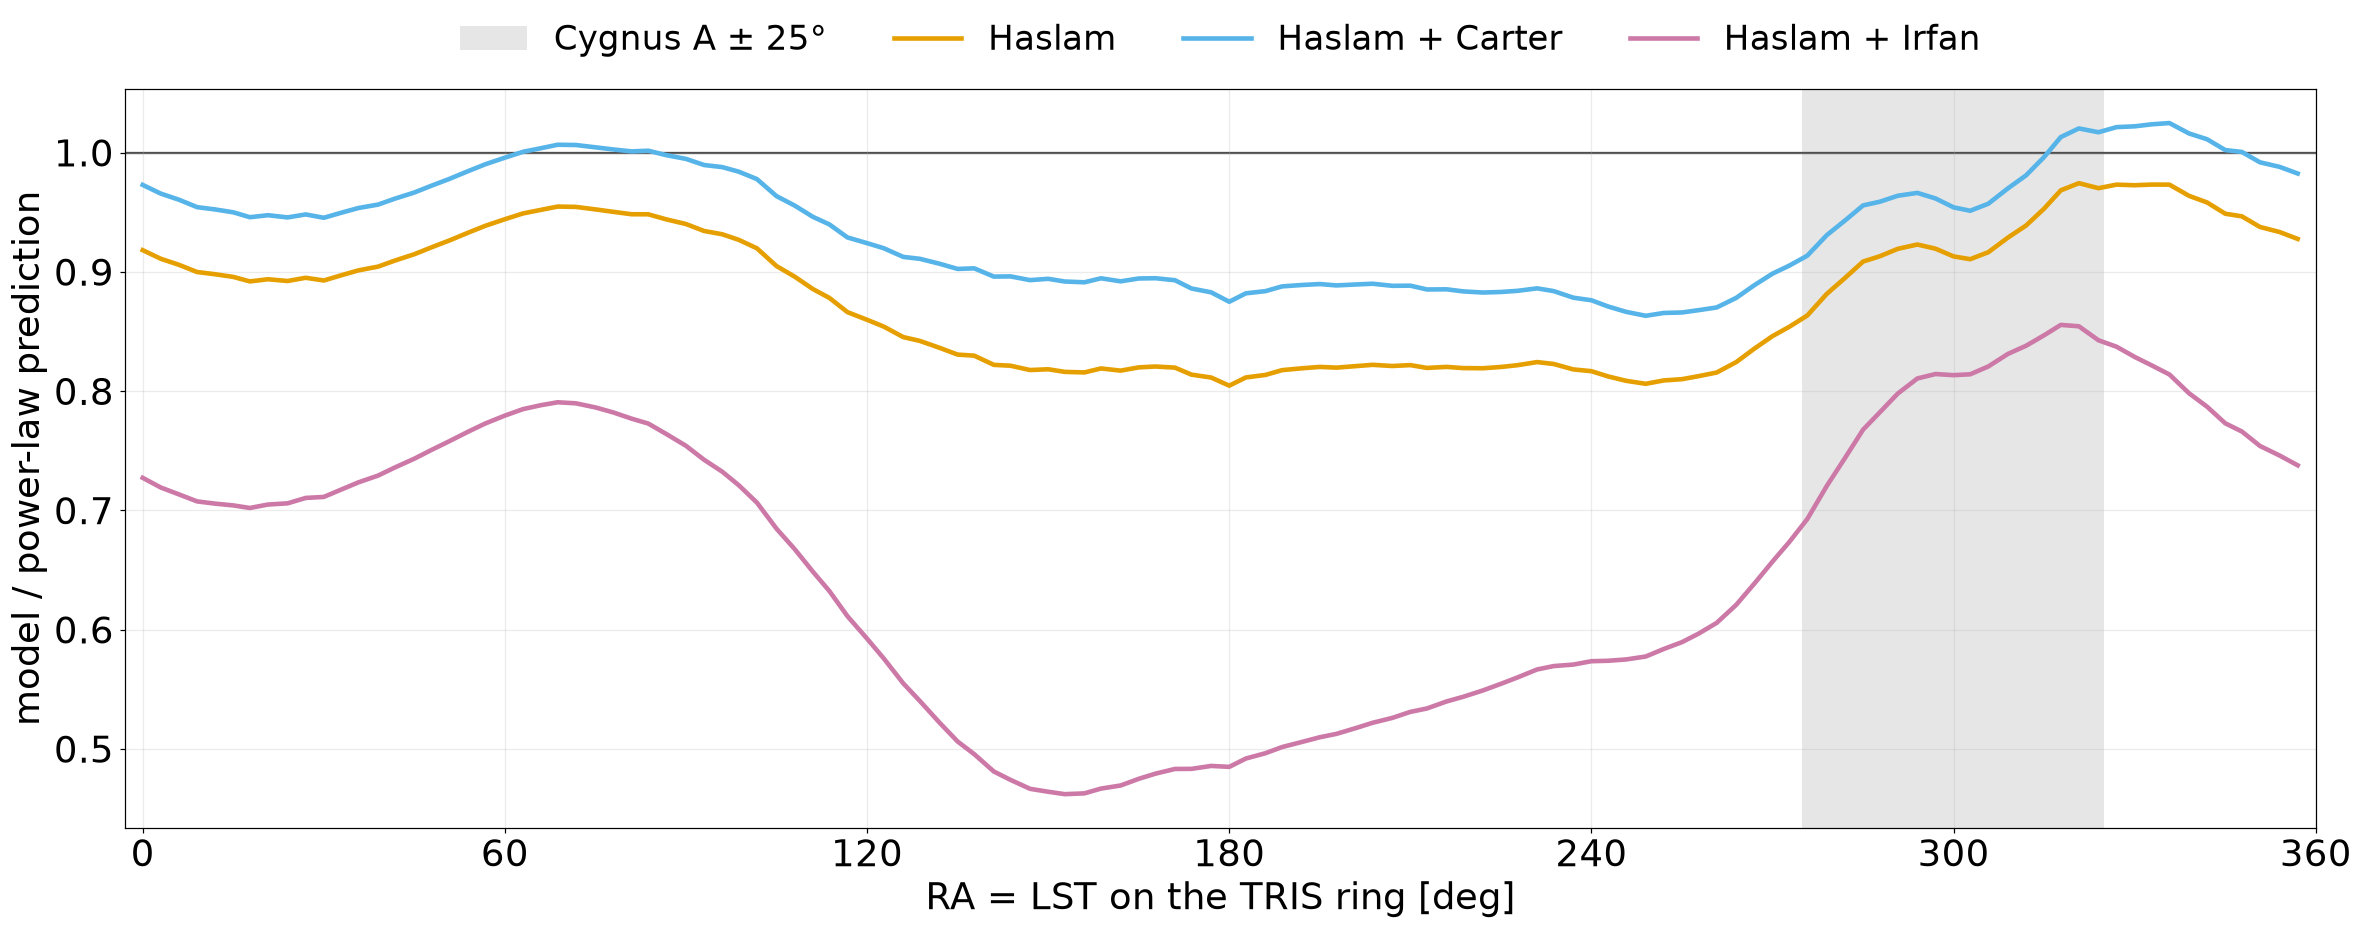

saved test_outputs/plot3_haslam_vs_fit/fig3_ratio_along_ring.png


In [6]:
fig, ax = plt.subplots(figsize=(22, 9))
ax.axvspan(CYG_A_RA - CYG_HALF, CYG_A_RA + CYG_HALF, color="0.9", lw=0, zorder=0, label="Cygnus A ± 25°")
ax.axhline(1, color="0.3", lw=1.5, zorder=1)
for n in HASLAMS:
    ax.plot(RA, T_MOD[n] / A_PL, lw=3, color=COLOUR[n], label=SHORT[n], zorder=2)
ax.set_xlim(-3, 360); ax.set_xticks(np.arange(0, 361, 60))
ax.set_xlabel("RA = LST on the TRIS ring [deg]")
ax.set_ylabel("model / power-law prediction")
ax.grid(alpha=0.25)
ax.legend(frameon=False, ncol=4, loc="upper center", bbox_to_anchor=(0.5, 1.13))
fig.tight_layout()
save(fig, "fig3_ratio_along_ring")

### Table — fit and ratio for every model

For each of the seven models: a, σ_a, b, σ_b, χ²/ν, the number of samples, and the mean and median of
model / prediction. There are two versions: all samples, and with RA 299.9 ± 25° excluded. This is pipeline step 6's
`scale_offset_408.csv`. **σ are underestimates** (correlated samples).

In [7]:
tab = SO                                         # pipeline step 6's table (read in section 2)
print(f"{SO_CSV.relative_to(REPO)}  (pipeline step 6; σ inflated by √(χ²/ν) when > 1)\n")
with pd.option_context("display.width", 220):
    print(tab.round(3).to_string(index=False))


paper_outputs/pipeline/step6_predict_408/scale_offset_408.csv  (pipeline step 6; σ inflated by √(χ²/ν) when > 1)

                 samples                     model  slope a   σ_a  intercept b [K]  σ_b [K]  χ²/ν  N samples  mean ratio  median ratio
                     all      Haslam (uncorrected)    1.017 0.038           -3.865    1.138 0.063        120       0.881         0.893
                     all Haslam, Carter correction    1.046 0.039           -3.068    1.167 0.063        120       0.939         0.946
                     all  Haslam, Irfan correction    1.018 0.035          -10.066    1.049 0.076        120       0.661         0.704
                     all                   GSM2008    1.018 0.038           -3.892    1.138 0.063        120       0.880         0.893
                     all                   GSM2016    0.960 0.039           -0.058    1.160 0.113        120       0.959         0.960
                     all GSM2016, GINAN correction    1.496 0.041          -

### Summary

Results from the run on 2026-10-27: 120 ring samples (103 without Cygnus A ± 25°), power law
maximum-likelihood prediction, `york` with σ scaled by √(χ²/ν) where χ²/ν > 1 (χ²/ν is 0.04–0.24 for
every model, so no fit is scaled). **Every σ is an underestimate** (correlated samples, roughly ×2.6;
Haslam's common error treated as independent), and a and b are strongly anti-correlated.

* **Haslam (uncorrected): scale a = 1.021 ± 0.038, offset b = −3.94 ± 1.14 K.** The slope is within 1σ
  of 1; the intercept is 3.9 K below 0. Haslam / prediction has a median of 0.894 (mean 0.882) and runs
  from about 0.81 (RA ≈ 180° and 250°) to 0.98 (RA ≈ 320–330°).
* **Carter moves the offset toward 0 and the scale away from 1; Irfan moves the offset away from 0.**
  Carter: a = 1.050 ± 0.039, b = −3.14 ± 1.17 K (b up by 0.80 K, a up by 0.029); median ratio 0.947.
  Irfan: a = 1.022 ± 0.035, b = −10.14 ± 1.05 K (b down by 6.2 K, a unchanged); median ratio 0.705.
* **GSM2016 + GINAN is the farthest point:** a = 1.492 ± 0.041, b = −16.0 ± 1.2 K. Its median ratio
  is 1.016 (mean 0.927).
* **GSM2016 is the closest point to (1, 0):** a = 0.958 ± 0.039, b = +0.02 ± 1.16 K, median ratio
  0.962. GSM2008 sits on top of uncorrected Haslam (a = 1.020, b = −3.93 K). LFSM is at a = 0.980 ± 0.038,
  b = −2.56 ± 1.14 K, median ratio 0.885.
* **Excluding Cygnus A ± 25° moves the slopes up and the offsets down.** Haslam goes to a = 1.055 ± 0.054,
  b = −4.77 ± 1.47 K (median ratio 0.861) and Carter to a = 1.085, b = −3.99 K. GSM2016 moves the most
  among the models near (1, 0): a = 1.053, b = −2.29 K. LFSM moves least (a = 0.990, b = −2.84 K) and
  GINAN goes to a = 1.616, b = −18.96 K. All the Haslam shifts are within 1σ of the all-sample fit.

In [8]:
# Total notebook run time: from the first code cell (which sets _NB_T0) to here.
import time as _nb_time
if "_NB_T0" in globals():
    _dt = _nb_time.time() - _NB_T0
    print(f"total notebook run time: {_dt:.0f} s ({int(_dt // 3600)}h {int(_dt % 3600 // 60):02d}m {int(_dt % 60):02d}s)")
else:
    print("total notebook run time: not recorded (the first code cell was not run)")

total notebook run time: 2 s (0h 00m 02s)
